# 01 · Preprocessing — Rendeiro 2020 Chronic Lymphocytic Leukemia (malignant compartment)

Isolate the malignant CLL B-cells, threshold thin samples by a **data-driven multiplicative gap**,
integrate patients (Harmony on `sample`), embed, remove detached islands, and read **Gate 1**
(sample-mixing + manifold continuity) off the regenerated embedding plus a per-neighbourhood metric
(iLISI) across an integration-strength (theta) sweep — never a scalar alone.

Rendeiro 2020 is peripheral-blood CLL profiled by 10x over a longitudinal ibrutinib cohort. After
thresholding, **7 malignant samples from 3 patients** (CLL1, CLL5, CLL6, CLL8) remain. Each patient's
leukaemia carries its own clonal genetics and CNV background, so raw patient segregation is expected
and strong Harmony integration is required. The blasts are a partly-cycling circulating population;
there is no separable proliferative lobe (checked below). Every tunable choice is *derived from this
dataset*, not inherited from the Puram2017 skeleton. Deliverable: `processed.h5ad`, `samples.pdf`.

In [1]:
import os, sys, glob, warnings
os.environ['R_HOME'] = sys.exec_prefix + '/lib/R/'
warnings.filterwarnings('ignore')
import numpy as np, pandas as pd
import scanpy as sc, scanpy.external as sce, scFates as scf
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from scipy.sparse.csgraph import connected_components
sc.settings.verbosity = 1
SEED = 1; np.random.seed(SEED)

In [2]:
# cwd = <root>/cancer/vertebrate/CCCA/Claude/<Category>/<Dataset>  (two levels below Puram)
name = os.path.basename(os.getcwd())                    # Rendeiro2020_Hematologic-1
cat  = os.path.basename(os.path.dirname(os.getcwd()))   # Hematologic
pth  = os.path.join(*([os.pardir]*6))                   # -> MesenCoder root
pth_data = os.path.join(pth, 'data')
sys.path.append(os.path.join(pth, 'cancer', 'vertebrate', 'CCCA'))
from scripts.load import load_CCCA_adata

# input folder = dataset name minus the '-1' re-analysis suffix
raw_name = 'Data_' + name.replace('-1','')
pth_in  = os.path.join(pth_data, 'unzip', 'CCCA', raw_name)
pth_out = os.path.join(pth_data, 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_fig = os.path.join(pth, 'figures', 'cancer', 'vertebrate', 'CCCA', 'Claude', cat, name)
pth_cb  = os.path.join(pth_fig, 'colorbars')
os.makedirs(pth_out, exist_ok=True); os.makedirs(pth_cb, exist_ok=True)
print('dataset:', name, '| category:', cat, '| raw:', raw_name)

dataset: Rendeiro2020_Hematologic-1 | category: Hematologic | raw: Data_Rendeiro2020_Hematologic


### Load malignant compartment
The loader auto-detects UMI counts (`Exp_data_UMIcounts.mtx`), normalizes total + `log1p`, and exposes
the publication `cell_type` annotation as `celltype`. Rendeiro et al. supply an explicit `Malignant`
call (the CLL leukaemic B-cells); we take that call directly and drop the normal PBMC compartment
(T/NK/macrophage), per protocol — use the publication's malignant call plus data-derived markers.

In [3]:
adata = load_CCCA_adata(pth_in, verbose=False)
adata.var_names_make_unique()
print('full atlas:', adata.shape)
print('cell types:', adata.obs['celltype'].value_counts().to_dict())
adata = adata[adata.obs['celltype'] == 'Malignant'].copy()
print('malignant:', adata.shape, '| samples:', adata.obs['sample'].nunique(),
      '| patients:', adata.obs['patient'].nunique())
print('expression: X max %.2f (log1p of normalize_total counts)' % adata.X.max())

full atlas: (48016, 18402)
cell types: {'Malignant': 18854, 'T_NK_cell': 6954, 'Macrophage': 2246, 'T_cell': 1455, 'NK_cell': 569}
malignant: (18854, 18402) | samples: 11 | patients: 4
expression: X max 6.35 (log1p of normalize_total counts)


### Sample thresholding — derived by multiplicative gap-finding
Sort per-sample malignant counts and cut at the geometric mean of the largest **multiplicative** gap
(the natural separatrix between tumour-bearing samples and spillover). Here the sorted counts fall off a
clean cliff (1012 -> 80, a 12.6x drop), so the gap rule is well-posed and drops the four sparse
late-timepoint samples, keeping 7 samples across 3 patients.

In [4]:
n = adata.obs['sample'].value_counts()
vals = n.values.astype(float)
ratios = vals[:-1] / vals[1:]
gap = int(np.argmax(ratios)); thresh = int(np.sqrt(vals[gap]*vals[gap+1]))
print('sorted per-sample counts:', dict(zip(n.index, n.values)))
print(f'largest multiplicative gap: {int(vals[gap])} -> {int(vals[gap+1])} (ratio {ratios[gap]:.2f})')
print(f'derived threshold (geometric mean across the gap) = {thresh}')
keep = n.index[n >= thresh]
adata = adata[adata.obs['sample'].isin(keep)].copy()
print(f'kept {len(keep)}/{len(n)} samples -> {adata.shape[0]} cells; patients kept:',
      sorted(adata.obs['patient'].unique().tolist()))

sorted per-sample counts: {'CLL5_d0': np.int64(5074), 'CLL6_d30': np.int64(4353), 'CLL5_d30': np.int64(2818), 'CLL1_d0': np.int64(2267), 'CLL6_d120': np.int64(1575), 'CLL8_d0': np.int64(1558), 'CLL6_d0': np.int64(1012), 'CLL5_d150': np.int64(80), 'CLL8_d30': np.int64(78), 'CLL6_d280': np.int64(33), 'CLL1_d120': np.int64(6)}
largest multiplicative gap: 1012 -> 80 (ratio 12.65)
derived threshold (geometric mean across the gap) = 284
kept 7/11 samples -> 18657 cells; patients kept: ['CLL1', 'CLL5', 'CLL6', 'CLL8']


### Cell cycle (de-novo — publication ships no phase calls)
Rendeiro's metadata carries no cell-cycle annotation, so we score S / G2M with the Tirosh regev gene
lists (`score_genes_cell_cycle`) and expose `cell_cycle_phase`, `g1s_score`, `g2m_score`. CLL is a
partly-cycling circulating leukaemia; we track the proliferative signal to check (in 02) that the
developmental axis is not a cell-cycle confound.

In [5]:
s_genes=['MCM5','PCNA','TYMS','FEN1','MCM2','MCM4','RRM1','UNG','GINS2','MCM6','CDCA7','DTL','PRIM1','UHRF1','HELLS','RFC2','RPA2','NASP','RAD51AP1','GMNN','WDR76','SLBP','CCNE2','UBR7','POLD3','MSH2','ATAD2','RAD51','RRM2','CDC45','CDC6','EXO1','TIPIN','DSCC1','BLM','CASP8AP2','USP1','CLSPN','POLA1','CHAF1B','BRIP1','E2F8']
g2m_genes=['HMGB2','CDK1','NUSAP1','UBE2C','BIRC5','TPX2','TOP2A','NDC80','CKS2','NUF2','CKS1B','MKI67','TMPO','CENPF','TACC3','FAM64A','SMC4','CCNB2','CKAP2L','CKAP2','AURKB','BUB1','KIF11','ANP32E','TUBB4B','GTSE1','KIF20B','HJURP','CDCA3','HN1','CDC20','TTK','CDC25C','KIF2C','RANGAP1','NCAPD2','DLGAP5','CDCA2','CDCA8','ECT2','KIF23','HMMR','AURKA','PSRC1','ANLN','LBR','CKAP5','CENPE','CTCF','NEK2','G2E3','GAS2L3','CBX5','CENPA']
sc.tl.score_genes_cell_cycle(adata, s_genes=[g for g in s_genes if g in adata.var_names],
                             g2m_genes=[g for g in g2m_genes if g in adata.var_names])
adata.obs['g1s_score']=adata.obs['S_score']; adata.obs['g2m_score']=adata.obs['G2M_score']
adata.obs['cell_cycle_phase']=adata.obs['phase']
print('cell-cycle phases:', adata.obs['phase'].value_counts().to_dict())

cell-cycle phases: {'G1': 10488, 'S': 7376, 'G2M': 793}


### Overdispersion, PCA, Harmony integration, embedding
Overdispersed-gene selection (scFates GAM), PCA, then Harmony on `sample`. `theta` is chosen by an
integration-strength sweep read on a per-neighbourhood metric (iLISI = effective #samples in each
cell's neighbourhood) — we take the smallest theta past which mixing plateaus. Pre-Harmony iLISI is ~1
(fully patient-segregated, as expected for genetically distinct CLL clones); at theta=2 the manifold is
still split into two patient blobs, so under-integration is rejected. Mixing rises sharply to theta=5
(iLISI 4.74) and only marginally to theta=10 (4.95), so **theta=5** is selected — the smallest theta
that resolves the split without over-collapsing. PC count (20) and UMAP spread (1.3) follow the 10x
precedents (Kürten/Sun/Lee/Zhou/Caron, comparable cell counts).

In [6]:
sc.pp.filter_genes(adata, min_cells=3)
scf.pp.find_overdispersed(adata)
print('overdispersed genes:', int(adata.var.highly_variable.sum()))
sc.pp.pca(adata, n_comps=50)

def ilisi(rep, labels, k=90):
    idx = NearestNeighbors(n_neighbors=k+1).fit(rep).kneighbors(rep, return_distance=False)[:,1:]
    codes = pd.Categorical(labels).codes; L=codes[idx]; out=np.empty(len(rep))
    for i in range(len(rep)):
        _,cnt=np.unique(L[i],return_counts=True); p=cnt/k; out[i]=1.0/np.sum(p**2)
    return out
samp = adata.obs['sample'].values; n_samp = adata.obs['sample'].nunique()
il_pre = np.median(ilisi(adata.obsm['X_pca'][:,:20], samp))
print(f'pre-Harmony iLISI median = {il_pre:.2f} of {n_samp} samples (fully patient-segregated)')
sweep = {}
for th in [2, 5, 10]:
    sce.pp.harmony_integrate(adata, 'sample', theta=th, max_iter_harmony=20, random_state=SEED)
    sweep[th] = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], samp))
print('theta sweep iLISI median (20 PC):', {k: round(v,2) for k,v in sweep.items()})
theta = 5
print('selected theta =', theta, '(two-blob split resolves by theta=5; mixing plateaus, no collapse)')
sce.pp.harmony_integrate(adata, 'sample', theta=theta, max_iter_harmony=20, random_state=SEED)
sc.pp.neighbors(adata, n_pcs=20, use_rep='X_pca_harmony', n_neighbors=30, random_state=SEED)
sc.tl.umap(adata, spread=1.3, random_state=SEED)

Finding overdispersed features
    computing mean and variances
    gam fitting
    found 528 over-dispersed features (0:00:01) --> added 
    .var['res'], residuals of GAM fit.
    .var['lp'], p-value.
    .var['lpa'], BH adjusted p-value.
    .var['qv'], percentile of qui-squared distribution.
    .var['highly_variable'], feature is over-dispersed.

overdispersed genes: 528
pre-Harmony iLISI median = 1.00 of 7 samples (fully patient-segregated)
theta sweep iLISI median (20 PC): {2: np.float64(2.93), 5: np.float64(4.74), 10: np.float64(4.95)}
selected theta = 5 (two-blob split resolves by theta=5; mixing plateaus, no collapse)


### Remove detached islands (data-driven)
Build a radius graph on the UMAP (6x the median nearest-neighbour distance) and drop any cell outside
the main connected component — stripping physically detached specks while keeping the continuous body.

In [7]:
um = adata.obsm['X_umap']
d,_ = NearestNeighbors(n_neighbors=6).fit(um).kneighbors(um)
adj = NearestNeighbors(radius=6*np.median(d[:,1:])).fit(um).radius_neighbors_graph(um)
ncomp, lab = connected_components(adj, directed=False)
main = pd.Series(lab).value_counts().index[0]
print(f'connected components: {ncomp}; removing {int((lab!=main).sum())} cells in {ncomp-1} detached islands')
adata = adata[lab==main].copy()
print('after island removal:', adata.shape)

connected components: 11; removing 166 cells in 10 detached islands
after island removal: (18491, 14889)


### Compartment probe + cell-cycle confound check (data-driven)
Low-resolution Leiden (res=0.15) probes for separable lobes. CLL's malignant manifold is a **single
compartment** at res=0.15 — there is no discrete proliferative lobe to scope out, even though a
substantial fraction of cells are cycling. Proliferation is diffuse across the cloud rather than
segregated, so the whole manifold is carried into the trajectory (verified against the developmental
axis in 02).

In [8]:
sc.tl.leiden(adata, resolution=0.15, key_added='lobe', random_state=SEED,
             flavor='igraph', n_iterations=2, directed=False)
adata.obs['cycling'] = adata.obs['cell_cycle_phase'].isin(['S','G2M'])
cyc = adata.obs.groupby('lobe', observed=True)['cycling'].mean()
print('lobe sizes:', adata.obs['lobe'].value_counts().to_dict())
print('cycling fraction per lobe:', cyc.round(2).to_dict())
print(f'{adata.obs["lobe"].nunique()} lobe(s) at res=0.15; cycling fraction overall '
      f'{adata.obs["cycling"].mean():.2f} (diffuse, not a separable proliferative compartment)')

lobe sizes: {'0': 18491}
cycling fraction per lobe: {'0': 0.44}
1 lobe(s) at res=0.15; cycling fraction overall 0.44 (diffuse, not a separable proliferative compartment)


### House orientation — one consistent layout for every UMAP
The developmental axis is diagonal in the raw joint embedding, so all trajectory panels are shown after
a single **rigid rotation** to a house horizontal layout (distance-preserving — *not* a re-embedding).
Derived **once here** from the manifold's axis of maximal variance; the sign is fixed in 02 against
pseudotime (Gast/pSom-high developmental origin on the left). Stored as `X_umap_lin`, re-used unchanged
by 02/03/04 (binding: one orientation across all deliverables).

In [9]:
xy = adata.obsm['X_umap']; c = xy - xy.mean(0)
aspect = c.std(0).max() / c.std(0).min()
_,_,vt = np.linalg.svd(c, full_matrices=False)          # vt[0] = axis of maximal variance
th_rot = np.arctan2(vt[0,1], vt[0,0])
Rm = np.array([[np.cos(-th_rot),-np.sin(-th_rot)],[np.sin(-th_rot),np.cos(-th_rot)]])
adata.obsm['X_umap_lin'] = c @ Rm.T
print(f'manifold aspect (max/min std): {aspect:.2f}')
print(f'house orientation: rigid rotation {np.degrees(th_rot):+.1f}deg (distances preserved); '
      f'stored as X_umap_lin, sign fixed against pseudotime in 02')

manifold aspect (max/min std): 1.28
house orientation: rigid rotation -98.3deg (distances preserved); stored as X_umap_lin, sign fixed against pseudotime in 02


### Gate 1 — batch mixing & manifold continuity (read on the embedding + iLISI)
Samples must intermix (no per-patient island) on one continuous manifold. The read is made on the
regenerated embedding itself (below) plus per-neighbourhood iLISI across the theta sweep — not a scalar
alone. Pre-Harmony iLISI ~1 (fully segregated) rises to ~4.7/7 at theta=5; the three patients
(CLL1/5/6/8) overlap across the cloud rather than forming separate islands, and a single connected
component remains after island removal. **Gate 1 = GO.**

iLISI median: pre-Harmony 1.00 -> post-Harmony(theta=5) 4.73 of 7 samples
7 samples / 4 patients share one continuous manifold (one connected component after island removal)
patients overlap across the cloud rather than segregating into islands
Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO


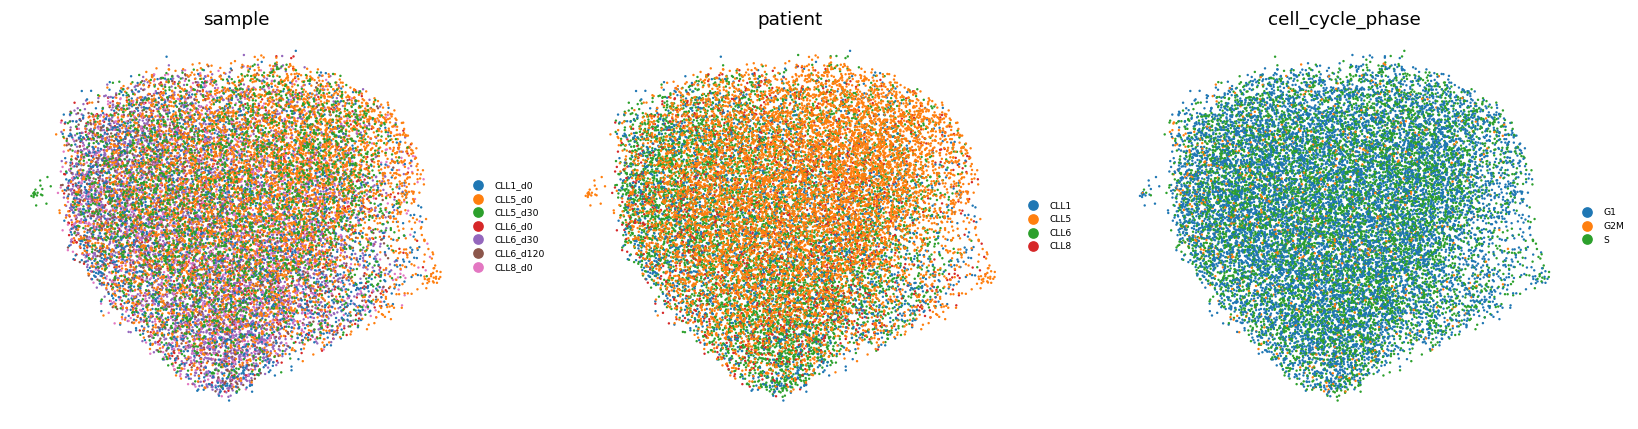

In [10]:
il_post = np.median(ilisi(adata.obsm['X_pca_harmony'][:,:20], adata.obs['sample'].values))
print(f'iLISI median: pre-Harmony {il_pre:.2f} -> post-Harmony(theta={theta}) {il_post:.2f} of {n_samp} samples')
print(f'{n_samp} samples / {adata.obs["patient"].nunique()} patients share one continuous manifold '
      f'(one connected component after island removal)')
print('patients overlap across the cloud rather than segregating into islands')
print('Gate 1: samples intermix per-neighbourhood on one continuous manifold -> GO')
# regenerated embedding: sample / patient / cell cycle (house orientation)
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax,col in zip(axes, ['sample','patient','cell_cycle_phase']):
    sc.pl.umap(plot, color=col, size=10, frameon=False, show=False, ax=ax,
               legend_fontsize=6, title=col)
fig.tight_layout()

### Save processed data

In [11]:
for c in adata.obs.columns:
    col = adata.obs[c]
    if col.dtype == object:
        conv = pd.to_numeric(col, errors='coerce')
        keep_num = col.notna().sum()>0 and conv.notna().sum() >= 0.9*col.notna().sum()
        adata.obs[c] = conv if keep_num else col.astype(str)
adata.write(os.path.join(pth_out, 'processed.h5ad'))
print('saved processed.h5ad', adata.shape)

saved processed.h5ad (18491, 14889)


### Sample-integration figure (deliverable) — house style `(3.5,1.5)` horizontal strip

saved samples.pdf | cells: 18491


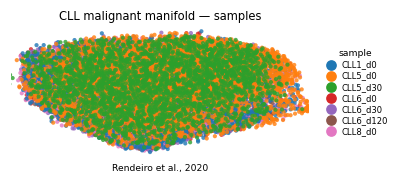

In [12]:
plot = adata.copy(); plot.obsm['X_umap'] = plot.obsm['X_umap_lin']
xl = plot.obsm['X_umap']
xlo,xhi = np.percentile(xl[:,0],[0.3,99.7]); ylo,yhi = np.percentile(xl[:,1],[0.3,99.7])
px=(xhi-xlo)*.05; py=(yhi-ylo)*.08
fig, ax = plt.subplots(figsize=(3.5,1.5))
sc.pl.umap(plot, color='sample', size=30, alpha=.8, frameon=False, show=False, ax=ax)
h,l = ax.get_legend_handles_labels()
ax.legend(h, l, ncol=1, frameon=False, loc='center left', bbox_to_anchor=(1.02,.5),
          handletextpad=.2, labelspacing=.25, fontsize=5.5, title='sample', title_fontsize=6)
ax.set_xlim(xlo-px,xhi+px); ax.set_ylim(ylo-py,yhi+py)
ax.set_title('CLL malignant manifold — samples', size=7.5)
ax.text(.5,-.12,'Rendeiro et al., 2020', ha='center', transform=ax.transAxes, size=6)
fig.savefig(os.path.join(pth_fig,'samples.pdf'), bbox_inches='tight')
print('saved samples.pdf | cells:', plot.shape[0])